In [2]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.svm import SVC, SVR
from sklearn.neural_network import MLPClassifier, MLPRegressor
import xgboost as xgb
import joblib
import warnings

warnings.filterwarnings('ignore')

np.random.seed(42)

In [3]:
# 1. Load Dataset


df = pd.read_csv('E:/final yr project/readmission/backend/diabetes_dataset.csv')

In [4]:
# Display basic information about the dataset
print("Dataset shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (5000, 24)

Data types:
Patient_ID                     int64
Age                          float64
Gender                        object
Ethnicity                     object
Family_History_Diabetes        int64
BMI                          float64
Systolic_BP                  float64
Diastolic_BP                 float64
Waist_Circumference          float64
Physical_Activity              int64
Smoking_Status                object
Alcohol_Consumption           object
Fasting_Glucose_mg_dL        float64
HbA1c_Percent                float64
HDL_mg_dL                    float64
LDL_mg_dL                    float64
Triglycerides_mg_dL          float64
Creatinine_mg_dL             float64
eGFR                         float64
Diabetes_Status                int64
Diabetes_Severity_Percent    float64
Neuropathy                   float64
Retinopathy                  float64
Nephropathy                  float64
dtype: object

Missing values:
Patient_ID                   0
Age        

In [5]:
y_class = df['Diabetes_Status']
y_reg = df['Diabetes_Severity_Percent']

# Define features (X)
features = [col for col in df.columns if col not in ['Patient_ID', 'Diabetes_Status', 'Diabetes_Severity_Percent']]
X = df[features]

# Identify numerical and categorical columns from the features
numerical_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(include='object').columns.tolist()

# 2. Preprocessing Pipeline
# ===============================================================

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ])

In [ ]:
# Train-test split
X_train, X_test, y_class_train, y_class_test, y_reg_train, y_reg_test = train_test_split(
    X, y_class, y_reg, test_size=0.2, random_state=42
)


In [7]:
print(df.columns)


Index(['Patient_ID', 'Age', 'Gender', 'Ethnicity', 'Family_History_Diabetes',
       'BMI', 'Systolic_BP', 'Diastolic_BP', 'Waist_Circumference',
       'Physical_Activity', 'Smoking_Status', 'Alcohol_Consumption',
       'Fasting_Glucose_mg_dL', 'HbA1c_Percent', 'HDL_mg_dL', 'LDL_mg_dL',
       'Triglycerides_mg_dL', 'Creatinine_mg_dL', 'eGFR', 'Diabetes_Status',
       'Diabetes_Severity_Percent', 'Neuropathy', 'Retinopathy',
       'Nephropathy'],
      dtype='object')


In [8]:
# Preprocess the data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Filter diabetic patients for regression
diabetic_mask_train = y_class_train == 1
diabetic_mask_test = y_class_test == 1

X_train_reg = X_train_processed[diabetic_mask_train]
y_reg_train = y_reg_train[diabetic_mask_train]
X_test_reg = X_test_processed[diabetic_mask_test]
y_reg_test = y_reg_test[diabetic_mask_test]

print("\nPreprocessing completed.")
print(f"Training samples: {X_train_processed.shape[0]}")
print(f"Testing samples: {X_test_processed.shape[0]}")
print(f"Diabetic patients (train): {X_train_reg.shape[0]}")
print(f"Diabetic patients (test): {X_test_reg.shape[0]}")


Preprocessing completed.
Training samples: 4000
Testing samples: 1000
Diabetic patients (train): 793
Diabetic patients (test): 173


Text(0.5, 1.0, 'Diabetes Status Distribution')

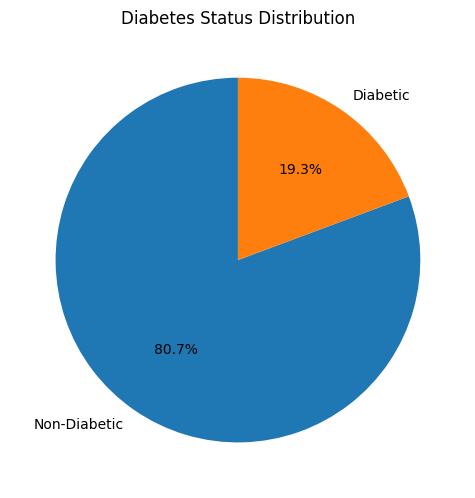

In [9]:
# 2. Data Visualization
plt.figure(figsize=(20, 15))

# 1. Pie chart for diabetes status distribution
plt.subplot(2, 3, 1)
diabetes_counts = df['Diabetes_Status'].value_counts()
plt.pie(diabetes_counts, labels=['Non-Diabetic', 'Diabetic'], autopct='%1.1f%%', startangle=90)
plt.title('Diabetes Status Distribution')

([0, 1, 2, 3, 4],
 [Text(0, 0, 'Caucasian'),
  Text(1, 0, 'Hispanic'),
  Text(2, 0, 'African American'),
  Text(3, 0, 'Asian'),
  Text(4, 0, 'Other')])

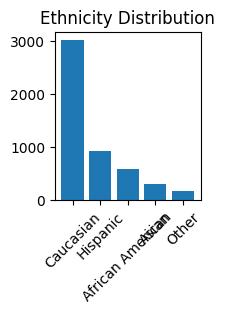

In [10]:
# 2. Bar chart for ethnicity distribution
plt.subplot(2, 3, 2)
ethnicity_counts = df['Ethnicity'].value_counts()
plt.bar(ethnicity_counts.index, ethnicity_counts.values)
plt.title('Ethnicity Distribution')
plt.xticks(rotation=45)

Text(0, 0.5, 'Frequency')

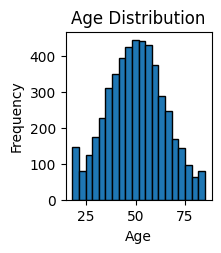

In [11]:
# 3. Histogram for age distribution
plt.subplot(2, 3, 3)
plt.hist(df['Age'], bins=20, edgecolor='black')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')

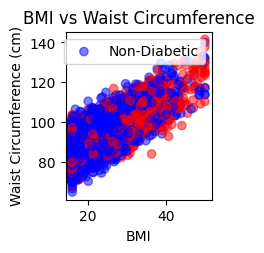

In [12]:
# 4. Scatter plot for BMI vs Waist Circumference
plt.subplot(2, 3, 4)
colors = ['blue' if status == 0 else 'red' for status in df['Diabetes_Status']]
plt.scatter(df['BMI'], df['Waist_Circumference'], c=colors, alpha=0.5)
plt.title('BMI vs Waist Circumference')
plt.xlabel('BMI')
plt.ylabel('Waist Circumference (cm)')
plt.legend(['Non-Diabetic', 'Diabetic'])

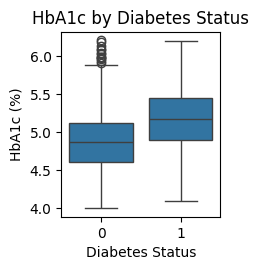

In [13]:
# 5. Box plot for HbA1c by Diabetes Status
plt.subplot(2, 3, 5)
sns.boxplot(x='Diabetes_Status', y='HbA1c_Percent', data=df)
plt.title('HbA1c by Diabetes Status')
plt.xlabel('Diabetes Status')
plt.ylabel('HbA1c (%)')

plt.tight_layout()
plt.show()

In [14]:
# 3. Classification Models
# ===============================================================

print("\nTraining Classification Models...")

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_processed, y_class_train)
lr_accuracy = accuracy_score(y_class_test, lr_model.predict(X_test_processed))

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_processed, y_class_train)
rf_accuracy = accuracy_score(y_class_test, rf_model.predict(X_test_processed))

xgb_class_model = xgb.XGBClassifier(random_state=42)
xgb_class_model.fit(X_train_processed, y_class_train)
xgb_class_accuracy = accuracy_score(y_class_test, xgb_class_model.predict(X_test_processed))

svm_model = SVC(probability=True, random_state=42)
svm_model.fit(X_train_processed, y_class_train)
svm_accuracy = accuracy_score(y_class_test, svm_model.predict(X_test_processed))

mlp_class_model = MLPClassifier(hidden_layer_sizes=(64, 32, 16), max_iter=500, random_state=42)
mlp_class_model.fit(X_train_processed, y_class_train)
mlp_class_accuracy = accuracy_score(y_class_test, mlp_class_model.predict(X_test_processed))

print(f"Logistic Regression Accuracy: {lr_accuracy*100:.2f}%")
print(f"Random Forest Accuracy: {rf_accuracy*100:.2f}%")
print(f"XGBoost Accuracy: {xgb_class_accuracy*100:.2f}%")
print(f"SVM Accuracy: {svm_accuracy*100:.2f}%")
print(f"MLP Accuracy: {mlp_class_accuracy*100:.2f}%")

# Best classification model
class_models = {
    'Logistic Regression': (lr_model, lr_accuracy),
    'Random Forest': (rf_model, rf_accuracy),
    'XGBoost': (xgb_class_model, xgb_class_accuracy),
    'SVM': (svm_model, svm_accuracy),
    'MLP Classifier': (mlp_class_model, mlp_class_accuracy)
}

best_class_name = max(class_models, key=lambda k: class_models[k][1])
best_class_model = class_models[best_class_name][0]

print(f"\nBest Classification Model: {best_class_name}")



Training Classification Models...
Logistic Regression Accuracy: 94.40%
Random Forest Accuracy: 95.10%
XGBoost Accuracy: 95.20%
SVM Accuracy: 94.60%
MLP Accuracy: 93.60%

Best Classification Model: XGBoost


In [15]:
# 4. Regression Models


print("\nTraining Regression Models...")

lin_reg_model = LinearRegression()
lin_reg_model.fit(X_train_reg, y_reg_train)
lin_reg_r2 = r2_score(y_reg_test, lin_reg_model.predict(X_test_reg))

rf_reg_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_reg_model.fit(X_train_reg, y_reg_train)
rf_reg_r2 = r2_score(y_reg_test, rf_reg_model.predict(X_test_reg))

xgb_reg_model = xgb.XGBRegressor(random_state=42)
xgb_reg_model.fit(X_train_reg, y_reg_train)
xgb_reg_r2 = r2_score(y_reg_test, xgb_reg_model.predict(X_test_reg))

svr_model = SVR()
svr_model.fit(X_train_reg, y_reg_train)
svr_r2 = r2_score(y_reg_test, svr_model.predict(X_test_reg))

mlp_reg_model = MLPRegressor(hidden_layer_sizes=(64, 32, 16), max_iter=500, random_state=42)
mlp_reg_model.fit(X_train_reg, y_reg_train)
mlp_reg_r2 = r2_score(y_reg_test, mlp_reg_model.predict(X_test_reg))

print(f"Linear Regression R2: {lin_reg_r2:.2f}")
print(f"Random Forest R2: {rf_reg_r2:.2f}")
print(f"XGBoost R2: {xgb_reg_r2:.2f}")
print(f"SVR R2: {svr_r2:.2f}")
print(f"MLP R2: {mlp_reg_r2:.2f}")

# Best regression model
reg_models = {
    'Linear Regression': (lin_reg_model, lin_reg_r2),
    'Random Forest': (rf_reg_model, rf_reg_r2),
    'XGBoost': (xgb_reg_model, xgb_reg_r2),
    'SVR': (svr_model, svr_r2),
    'MLP Regressor': (mlp_reg_model, mlp_reg_r2)
}

best_reg_name = max(reg_models, key=lambda k: reg_models[k][1])
best_reg_model = reg_models[best_reg_name][0]

print(f"\nBest Regression Model: {best_reg_name}")


Training Regression Models...
Linear Regression R2: 0.54
Random Forest R2: 0.65
XGBoost R2: 0.70
SVR R2: 0.54
MLP R2: 0.54

Best Regression Model: XGBoost


In [16]:
# 5. Save Models
# ===============================================================

joblib.dump(best_class_model, "diabetic_model.pkl")

joblib.dump(preprocessor, "diabetic_preprocessor.pkl")

['diabetic_preprocessor.pkl']

In [ ]:
# ================== Load Model and Predict ==================

import pandas as pd
import joblib

# 1. Load the saved classification model and preprocessor
best_class_model = joblib.load("best_classification_model.pkl")
preprocessor = joblib.load("preprocessor.pkl")

# 2. Define the patient input (only provide available fields)
user_input = {
    'Age': 59,
    'Gender': 'Male',
    'Ethnicity': 'Hispanic',
    'Family_History_Diabetes': 0,
    'BMI': 44.3,
    'Systolic_BP': 145.37,
    'Diastolic_BP': 76.84,
    'Waist_Circumference': 117.7,
    'Physical_Activity': 0,
    'Smoking_Status': 'Former',
    'Alcohol_Consumption': 'Light',
    'Fasting_Glucose_mg_dL': 124.76,
    'HbA1c_Percent': 5.51
}

# 3. Fill missing features
all_features = ['Age','Gender','Ethnicity','Family_History_Diabetes','BMI',
                'Systolic_BP','Diastolic_BP','Waist_Circumference','Physical_Activity',
                'Smoking_Status','Alcohol_Consumption','Fasting_Glucose_mg_dL','HbA1c_Percent',
                'HDL_mg_dL','LDL_mg_dL','Triglycerides_mg_dL','Creatinine_mg_dL','eGFR',
                'Neuropathy','Retinopathy','Nephropathy']

sample_data = {feat: user_input.get(feat, 0 if feat not in ['Gender','Ethnicity','Smoking_Status','Alcohol_Consumption'] else 'Unknown') for feat in all_features}
sample_df = pd.DataFrame([sample_data])

# 4. Preprocess
sample_processed = preprocessor.transform(sample_df)

# 5. Predict classification and get confidence
class_prediction = best_class_model.predict(sample_processed)[0]
class_confidence = best_class_model.predict_proba(sample_processed)[0][1] * 100 if hasattr(best_class_model, 'predict_proba') else 100

# 6. Estimate severity from confidence (scale 0-100%)
severity_estimate = class_confidence * 0.5339  # you can adjust scaling

# 7. Report helper functions
def get_severity_level(sev):
    if sev <= 15: return 'Low Severity'
    elif sev <= 30: return 'Moderate Severity'
    else: return 'High Severity'

def get_readmission(sev):
    if sev <= 15: return 'No Re-admission Needed'
    elif sev <= 30: return 'Monitor Closely'
    else: return 'Re-admission Recommended'

def get_lifestyle_suggestion(status, sev):
    if status == 'Non-Diabetic':
        return ['Maintain healthy lifestyle with balanced diet and regular exercise.',
                'Keep monitoring fasting glucose periodically.',
                'Stay active and manage weight.']
    else:
        if sev <= 15: return ['Maintain balanced diet with more fruits and fibre.',
                               'Continue mild exercise (20–30 minutes/day).']
        elif sev <= 30: return ['Reduce sugar and processed food intake.',
                                 'Increase monitoring (weekly).',
                                 'Do moderate exercise (30–45 minutes/day).']
        else: return ['Immediate medical consultation.',
                      'Strict diet and daily glucose monitoring.',
                      'High-intensity supervised exercise as advised by doctor.']

def get_insurance_plan(status, sev):
    if status == 'Non-Diabetic': return 'No insurance needed – focus on healthy lifestyle'
    else:
        if sev <= 15: return 'HealthGuard Basic Diabetes Plan'
        elif sev <= 30: return 'WellLife Diabetes Care Plan'
        else: return 'PremiumDiab Complications Coverage Plan'

# 8. Generate report
predicted_status = 'Diabetic' if class_prediction == 1 else 'Non-Diabetic'
severity_level = get_severity_level(severity_estimate)
readmission = get_readmission(severity_estimate)
lifestyle_suggestions = get_lifestyle_suggestion(predicted_status, severity_estimate)
insurance_plan = get_insurance_plan(predicted_status, severity_estimate)

# 9. Display
print("\n" + "="*30)
print("====  PATIENT RESULT ====")
print("="*30)
print(f"Diabetes Status: {predicted_status}")
print(f"Confidence: {class_confidence:.2f}%")
print(f"Predicted Diabetes Severity: {severity_estimate:.2f}%\n")

print("=== Additional Patient Insights ===")
print(f"Readmission Decision: {readmission}")
print(f"Recommended Insurance Plan: {insurance_plan}\n")

print("Lifestyle Suggestions:")
for sug in lifestyle_suggestions:
    print(f"- {sug}")
print("="*30 + "\n")



====  PATIENT RESULT ====
Diabetes Status: Diabetic
Confidence: 95.42%
Predicted Diabetes Severity: 50.94%

=== Additional Patient Insights ===
Readmission Decision: Re-admission Recommended
Recommended Insurance Plan: PremiumDiab Complications Coverage Plan

Lifestyle Suggestions:
- Immediate medical consultation.
- Strict diet and daily glucose monitoring.
- High-intensity supervised exercise as advised by doctor.



In [ ]:
# ================== Load Model and Predict ==================

import pandas as pd
import joblib

# 1. Load the saved classification model and preprocessor
best_class_model = joblib.load("best_classification_model.pkl")
preprocessor = joblib.load("preprocessor.pkl")

# 2. Define the patient input
user_input = {
    'Age': 46,
    'Gender': 'Male',
    'Ethnicity': 'Caucasian',
    'Family_History_Diabetes': 0,
    'BMI': 20.49,
    'Systolic_BP': 102.68,
    'Diastolic_BP': 70.48,
    'Waist_Circumference': 96.39,
    'Physical_Activity': 0,
    'Smoking_Status': 'Never',
    'Alcohol_Consumption': 'Light',
    'Fasting_Glucose_mg_dL': 111.57,
    'HbA1c_Percent': 4.34
}

# 3. Fill missing features
all_features = ['Age','Gender','Ethnicity','Family_History_Diabetes','BMI',
                'Systolic_BP','Diastolic_BP','Waist_Circumference','Physical_Activity',
                'Smoking_Status','Alcohol_Consumption','Fasting_Glucose_mg_dL','HbA1c_Percent',
                'HDL_mg_dL','LDL_mg_dL','Triglycerides_mg_dL','Creatinine_mg_dL','eGFR',
                'Neuropathy','Retinopathy','Nephropathy']

sample_data = {feat: user_input.get(feat, 0 if feat not in ['Gender','Ethnicity','Smoking_Status','Alcohol_Consumption'] else 'Unknown') for feat in all_features}
sample_df = pd.DataFrame([sample_data])

# 4. Preprocess
sample_processed = preprocessor.transform(sample_df)

# 5. Predict classification and get confidence
class_prediction = best_class_model.predict(sample_processed)[0]
class_confidence = best_class_model.predict_proba(sample_processed)[0][1] * 100 if hasattr(best_class_model, 'predict_proba') else 100

# 6. Estimate severity from confidence (scale 0-100%)
severity_estimate = class_confidence * 0.5339  # adjust scaling if needed

# 7. Report helper functions
def get_severity_level(sev):
    if sev <= 15: return 'Low Severity'
    elif sev <= 30: return 'Moderate Severity'
    else: return 'High Severity'

def get_readmission(sev):
    if sev <= 15: return 'No Re-admission Needed'
    elif sev <= 30: return 'Monitor Closely'
    else: return 'Re-admission Recommended'

def get_lifestyle_suggestion(status, sev):
    if status == 'Non-Diabetic':
        return ['Maintain healthy lifestyle with balanced diet and regular exercise.',
                'Keep monitoring fasting glucose periodically.',
                'Stay active and manage weight.']
    else:
        if sev <= 15: return ['Maintain balanced diet with more fruits and fibre.',
                               'Continue mild exercise (20–30 minutes/day).']
        elif sev <= 30: return ['Reduce sugar and processed food intake.',
                                 'Increase monitoring (weekly).',
                                 'Do moderate exercise (30–45 minutes/day).']
        else: return ['Immediate medical consultation.',
                      'Strict diet and daily glucose monitoring.',
                      'High-intensity supervised exercise as advised by doctor.']

def get_insurance_plan(status, sev):
    if status == 'Non-Diabetic': return 'No insurance needed – focus on healthy lifestyle'
    else:
        if sev <= 15: return 'HealthGuard Basic Diabetes Plan'
        elif sev <= 30: return 'WellLife Diabetes Care Plan'
        else: return 'PremiumDiab Complications Coverage Plan'

# 8. Generate report
predicted_status = 'Diabetic' if class_prediction == 1 else 'Non-Diabetic'
severity_level = get_severity_level(severity_estimate)
readmission = get_readmission(severity_estimate)
lifestyle_suggestions = get_lifestyle_suggestion(predicted_status, severity_estimate)
insurance_plan = get_insurance_plan(predicted_status, severity_estimate)

# 9. Display
print("\n" + "="*30)
print("====  PATIENT RESULT ====")
print("="*30)
print(f"Diabetes Status: {predicted_status}")
print(f"Confidence: {class_confidence:.2f}%")
print(f"Predicted Diabetes Severity: {severity_estimate:.2f}%\n")

print("=== Additional Patient Insights ===")
print(f"Readmission Decision: {readmission}")
print(f"Recommended Insurance Plan: {insurance_plan}\n")

print("Lifestyle Suggestions:")
for sug in lifestyle_suggestions:
    print(f"- {sug}")
print("="*30 + "\n")



====  PATIENT RESULT ====
Diabetes Status: Non-Diabetic
Confidence: 2.81%
Predicted Diabetes Severity: 1.50%

=== Additional Patient Insights ===
Readmission Decision: No Re-admission Needed
Recommended Insurance Plan: No insurance needed – focus on healthy lifestyle

Lifestyle Suggestions:
- Maintain healthy lifestyle with balanced diet and regular exercise.
- Keep monitoring fasting glucose periodically.
- Stay active and manage weight.



In [ ]:
# ================== Load Model and Predict ==================

import pandas as pd
import joblib

# 1. Load the saved classification model and preprocessor
best_class_model = joblib.load("best_classification_model.pkl")
preprocessor = joblib.load("preprocessor.pkl")

# 2. Define the patient input
user_input = {
    'Age': 72,
    'Gender': 'Male',
    'Ethnicity': 'Caucasian',
    'Family_History_Diabetes': 0,
    'BMI': 32.52,
    'Systolic_BP': 137.82,
    'Diastolic_BP': 75.62,
    'Waist_Circumference': 104.90,
    'Physical_Activity': 1,
    'Smoking_Status': 'Never',
    'Alcohol_Consumption': 'Moderate',
    'Fasting_Glucose_mg_dL': 114.34,
    'HbA1c_Percent': 4.61
}

# 3. Fill missing features
all_features = ['Age','Gender','Ethnicity','Family_History_Diabetes','BMI',
                'Systolic_BP','Diastolic_BP','Waist_Circumference','Physical_Activity',
                'Smoking_Status','Alcohol_Consumption','Fasting_Glucose_mg_dL','HbA1c_Percent',
                'HDL_mg_dL','LDL_mg_dL','Triglycerides_mg_dL','Creatinine_mg_dL','eGFR',
                'Neuropathy','Retinopathy','Nephropathy']

sample_data = {feat: user_input.get(feat, 0 if feat not in ['Gender','Ethnicity','Smoking_Status','Alcohol_Consumption'] else 'Unknown') for feat in all_features}
sample_df = pd.DataFrame([sample_data])

# 4. Preprocess
sample_processed = preprocessor.transform(sample_df)

# 5. Predict classification and get confidence
class_prediction = best_class_model.predict(sample_processed)[0]
class_confidence = best_class_model.predict_proba(sample_processed)[0][1] * 100 if hasattr(best_class_model, 'predict_proba') else 100

# 6. Estimate severity from confidence (0-100%)
reg_prediction = class_confidence * 0.5339  # scale to match previous regression scale

# 7. Report helper functions
def get_severity_level(sev):
    if sev <= 15: return 'Low Severity'
    elif sev <= 30: return 'Moderate Severity'
    else: return 'High Severity'

def get_readmission(sev):
    if sev <= 15: return 'No Re-admission Needed'
    elif sev <= 30: return 'Monitor Closely'
    else: return 'Re-admission Recommended'

def get_lifestyle_suggestion(status, sev):
    if status == 'Non-Diabetic':
        return ['Maintain healthy lifestyle with balanced diet and regular exercise.',
                'Keep monitoring fasting glucose periodically.',
                'Stay active and manage weight.']
    else:
        if sev <= 15: return ['Maintain balanced diet with more fruits and fibre.',
                               'Continue mild exercise (20–30 minutes/day).']
        elif sev <= 30: return ['Reduce sugar and processed food intake.',
                                 'Increase monitoring (weekly).',
                                 'Do moderate exercise (30–45 minutes/day).']
        else: return ['Immediate medical consultation.',
                      'Strict diet and daily glucose monitoring.',
                      'High-intensity supervised exercise as advised by doctor.']

def get_insurance_plan(status, sev):
    if status == 'Non-Diabetic': return 'No insurance needed – focus on healthy lifestyle'
    else:
        if sev <= 15: return 'HealthGuard Basic Diabetes Plan'
        elif sev <= 30: return 'WellLife Diabetes Care Plan'
        else: return 'PremiumDiab Complications Coverage Plan'

# 8. Generate report
predicted_status = 'Diabetic' if class_prediction == 1 else 'Non-Diabetic'
severity_level = get_severity_level(reg_prediction)
readmission = get_readmission(reg_prediction)
lifestyle_suggestions = get_lifestyle_suggestion(predicted_status, reg_prediction)
insurance_plan = get_insurance_plan(predicted_status, reg_prediction)

# 9. Display
print("\n" + "="*30)
print("====  PATIENT RESULT ====")
print("="*30)
print(f"Diabetes Status: {predicted_status}")
print(f"Confidence: {class_confidence:.2f}%")
print(f"Predicted Diabetes Severity: {reg_prediction:.2f}%\n")

print("=== Additional Patient Insights ===")
print(f"Readmission Decision: {readmission}")
print(f"Recommended Insurance Plan: {insurance_plan}\n")

print("Lifestyle Suggestions:")
for sug in lifestyle_suggestions:
    print(f"- {sug}")
print("="*30 + "\n")



====  PATIENT RESULT ====
Diabetes Status: Diabetic
Confidence: 88.92%
Predicted Diabetes Severity: 47.47%

=== Additional Patient Insights ===
Readmission Decision: Re-admission Recommended
Recommended Insurance Plan: PremiumDiab Complications Coverage Plan

Lifestyle Suggestions:
- Immediate medical consultation.
- Strict diet and daily glucose monitoring.
- High-intensity supervised exercise as advised by doctor.

